In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
conn = sqlite3.connect(r"..\database\processed\earthquakes_API.db") # Connexión a .db
cursor = conn.cursor()

In [3]:
def run_query(query):
    return pd.read_sql_query(query, conn)

In [5]:
query = """
select is_ocean , count(*) as total 
from earthquakes_clean 
where is_ocean is not null 
group by is_ocean 
order by total desc;
"""

In [6]:
df = run_query(query)
print(df)

  is_ocean    total
0        0  2445684
1        1   644285


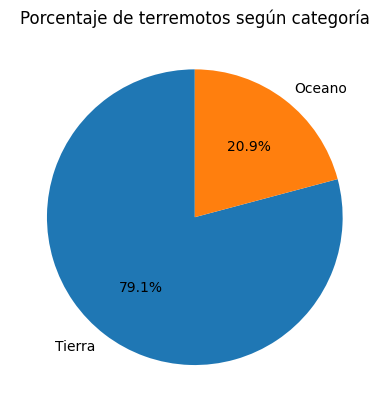

In [7]:
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"})
plt.pie(
    df["total"],
    labels=df["zona"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Porcentaje de terremotos según categoría")
plt.show()

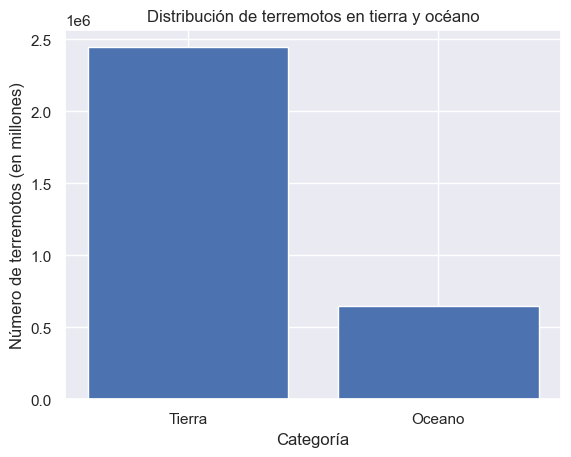

In [ ]:
plt.figure()
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"}) # Convierte 1/0 en Oceano y Tierra
plt.bar(df["zona"], df["total"]) # Define cada columna
plt.title("Distribución de terremotos en tierra y océano")
plt.xlabel("Categoría")
plt.ylabel("Número de terremotos (en millones)")

plt.show()

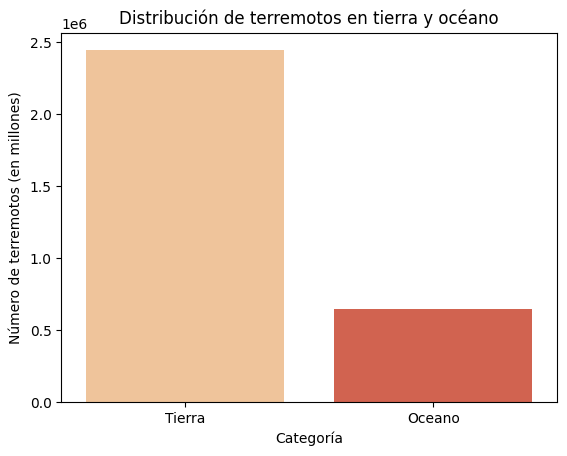

<Figure size 640x480 with 0 Axes>

In [8]:
df["zona"] = df["is_ocean"].astype(int).map({1:"Oceano", 0:"Tierra"})

plt.figure()

sns.barplot(
    x='zona',
    y='total',
    data=df,
    hue='zona',
    palette="OrRd",
    legend=False
)

plt.title("Distribución de terremotos en tierra y océano")
plt.xlabel("Categoría")
plt.ylabel("Número de terremotos (en millones)")

plt.show()
plt.savefig("../images/magnitudes.png", dpi=300, bbox_inches="tight")

In [132]:
query = """
select geo_country, count(*) as total
from earthquakes_clean
where geo_country is not null
and geo_country is not "Ocean"
group by geo_country
order by total desc
limit 10;
"""

In [133]:
df = run_query(query)
print(df)

                geo_country    total
0  United States of America  2230953
1                    Mexico    31211
2                    Canada    25165
3               Puerto Rico    16537
4                     Chile    15546
5                 Indonesia     9009
6                     Italy     8674
7                     China     8548
8                 Argentina     7998
9                    Greece     7215


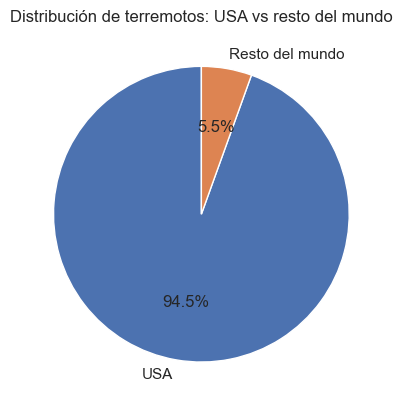

In [140]:
usa_total = df[df["geo_country"] == "United States of America"]["total"].values[0]
rest_total = df[df["geo_country"] != "United States of America"]["total"].sum()

df_usa = pd.DataFrame({
    "category": ["USA", "Resto del mundo"],
    "total": [usa_total, rest_total]
})

plt.figure()

plt.pie(
    df_usa["total"],
    labels=df_usa["category"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribución de terremotos: USA vs resto del mundo")

plt.show()

In [10]:
query = """
select geo_country, count(*) as total
from earthquakes_clean
where geo_country is not null
and mag > 4
and geo_country is not "Ocean"
group by geo_country
order by total desc
limit 10;
"""

In [11]:
df = run_query(query)
print(df)

        geo_country  total
0         Indonesia   7889
1             Chile   6493
2             China   6269
3  Papua New Guinea   5266
4         Argentina   4319
5              Iran   3433
6       Afghanistan   3250
7             Japan   3215
8              Peru   3196
9            Mexico   2945


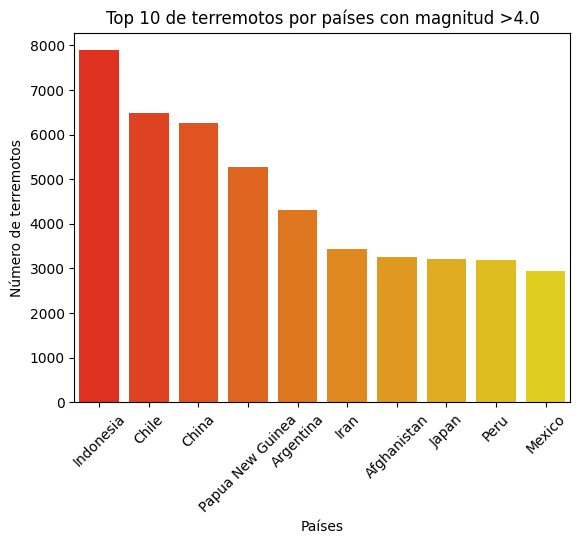

In [12]:
plt.figure()

sns.barplot(
    x='geo_country',
    y='total',
    data=df,
    hue='geo_country',
    palette="autumn",
    legend=False,
    

)

plt.title("Top 10 de terremotos por países con magnitud >4.0")
plt.xlabel("Países")
plt.ylabel("Número de terremotos")
plt.xticks(rotation=45)

plt.show()

In [124]:
query = """
select year, count(*) as total
from earthquakes_clean
group by year
order by year;
"""

In [125]:
df = run_query(query)
print(df)

    year   total
0   2000   69238
1   2001   70458
2   2002   89756
3   2003   96252
4   2004  110238
5   2005   99620
6   2006   98206
7   2007   93265
8   2008  120550
9   2009   85617
10  2010  119234
11  2011  102950
12  2012  101031
13  2013  108540
14  2014  129563
15  2015  119397
16  2016  118377
17  2017  127006
18  2018  175479
19  2019  171861
20  2020  187633
21  2021  153550
22  2022  139971
23  2023  138805
24  2024  137055
25  2025  126317


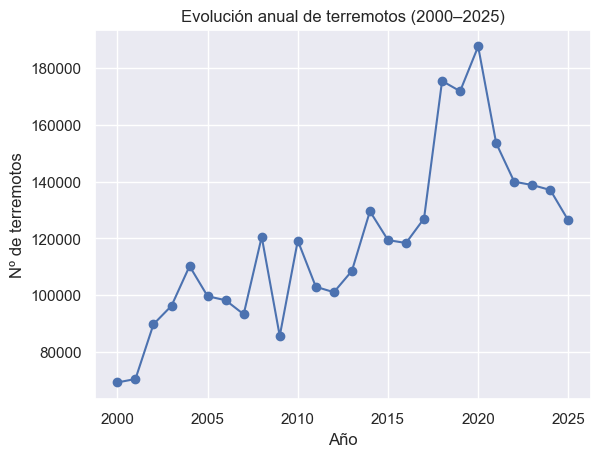

In [ ]:
plt.plot(df['year'],df['total'],marker="o") # X:year Y:total
plt.title("Evolución anual de terremotos (2000–2025)")
plt.xlabel("Año")
plt.ylabel("Nº de terremotos")
plt.show()

In [163]:
query = """
select 
    CASE 
        WHEN mag < 2 THEN 'Micro'
        WHEN mag >= 2 and mag < 4 THEN 'Menor'
        WHEN mag >= 4 and mag < 6 THEN 'Moderado'
        ELSE 'Fuerte'
    END AS Category,
    count(*) as N_earthquakes
from earthquakes_clean
group by Category
order by mag;
"""

In [164]:
df = run_query(query)
print(df)

   Category  N_earthquakes
0     Micro        2123649
1     Menor         619539
2  Moderado         343040
3    Fuerte           3741


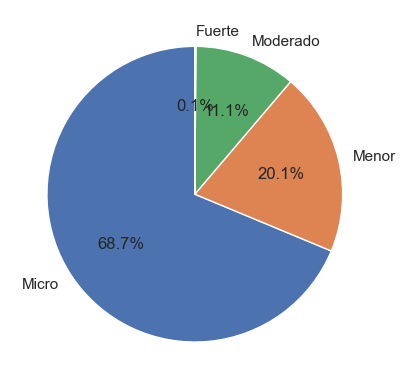

In [ ]:
plt.pie(
    df["N_earthquakes"],
    labels=df["Category"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Porcentage de terremotos por categoria")
plt.show()

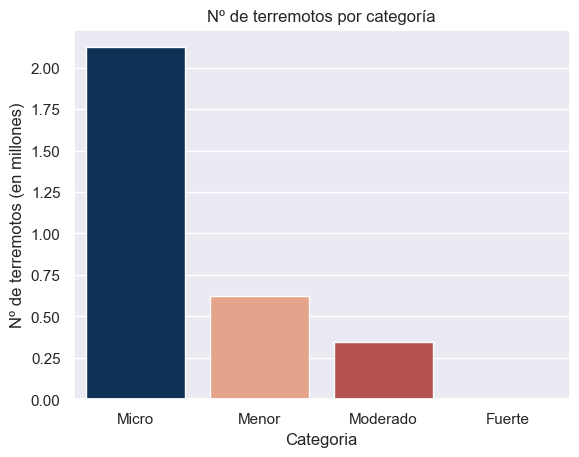

In [178]:
plt.figure()
df["millones"] = df["N_earthquakes"] / 1e6 # Evita que salga el 1e6 y mejora la lectura
sns.barplot(x=df["Category"],
            y=df["millones"],
            data=df,
            hue=df["millones"],
            palette="RdBu",
            legend=False)
plt.title("Nº de terremotos por categoría")
plt.xlabel("Categoria")
plt.ylabel("Nº de terremotos (en millones)")
#plt.ticklabel_format(style='',axis='y') 
plt.show()

In [4]:
query = """
select 
    case 
        when country = geo_country then 'equal'
        else 'not equal'
    end as Validation,
    count(*) as Total
from earthquakes_clean
group by Validation;
"""

In [85]:
df = run_query(query)
print(df)

  Validation    Total
0      equal   145917
1  not equal  2944052


In [13]:
query = """
select geo_country, mag, year, month, day
from earthquakes_clean
where geo_country is not 'Ocean'
order by mag desc
limit 10
"""

In [14]:
df = run_query(query)
print(df)

                geo_country  mag  year  month  day
0                 Indonesia  8.6  2005      3   28
1                      Peru  8.0  2019      5   26
2  United States of America  7.9  2002     11    3
3                     China  7.9  2008      5   12
4          Papua New Guinea  7.9  2017      1   22
5          Papua New Guinea  7.8  2000     11   17
6                     China  7.8  2001     11   14
7                     Chile  7.8  2005      6   13
8                    Canada  7.8  2012     10   28
9                     Nepal  7.8  2015      4   25


In [30]:
query = """
select year, geo_country, max(mag) as max_mag
from earthquakes_clean
where geo_country is not 'Ocean'
group by year
order by year
"""

In [31]:
df = run_query(query)
print(df)

    year               geo_country  max_mag
0   2000          Papua New Guinea      7.8
1   2001                     China      7.8
2   2002  United States of America      7.9
3   2003                    Russia      7.3
4   2004                 Indonesia      7.3
5   2005                 Indonesia      8.6
6   2006                    Russia      7.6
7   2007                     Chile      7.7
8   2008                     China      7.9
9   2009                 Indonesia      7.4
10  2010          Papua New Guinea      7.3
11  2011                  Pakistan      7.2
12  2012                    Canada      7.8
13  2013                      Iran      7.7
14  2014                    Mexico      7.2
15  2015                     Nepal      7.8
16  2016                   Ecuador      7.8
17  2017          Papua New Guinea      7.9
18  2018          Papua New Guinea      7.5
19  2019                      Peru      8.0
20  2020                    Mexico      7.4
21  2021                      Pe

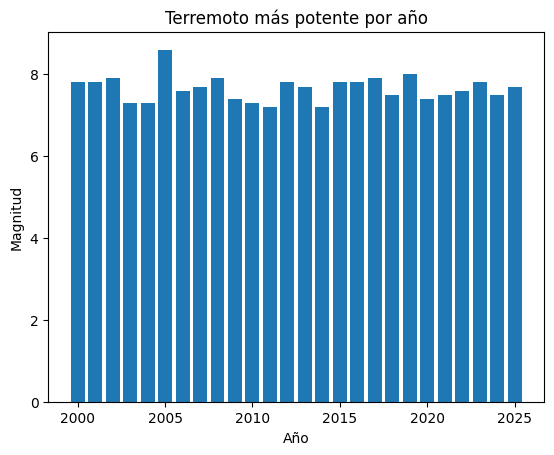

In [33]:
plt.figure()
plt.bar(df["year"],df["max_mag"])
plt.title("Terremoto más potente por año")
plt.xlabel("Año")
plt.ylabel("Magnitud")
plt.show()

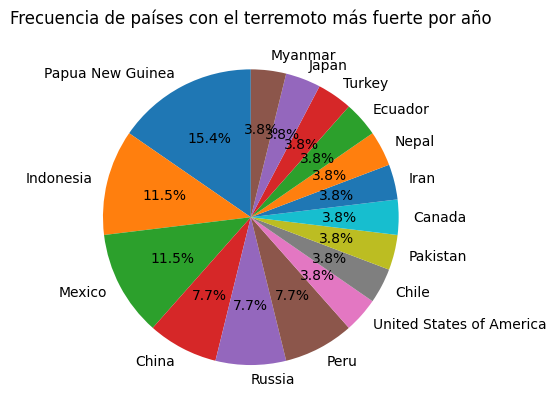

In [39]:
plt.figure()
df_counts = df["geo_country"].value_counts().reset_index()
df_counts.columns = ["geo_country", "count"]
plt.pie(
    df_counts['count'],
    labels=df_counts["geo_country"],
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Frecuencia de países con el terremoto más fuerte por año")
plt.show()